In [2]:
from environment import benchmark, F1TenthEnv, RoboRacerEnv
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import time


/Users/jacquesamsel/.pyenv/versions/skripsie2/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
f1tenth_env = F1TenthEnv(num_stacked_frames=50)

objc[84794]: Class SDLApplication is implemented in both /Users/jacquesamsel/.pyenv/versions/3.10.12/envs/skripsie2/lib/python3.10/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x120628890) and /Users/jacquesamsel/.pyenv/versions/3.10.12/envs/skripsie2/lib/python3.10/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x1424cd2c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[84794]: Class SDLAppDelegate is implemented in both /Users/jacquesamsel/.pyenv/versions/3.10.12/envs/skripsie2/lib/python3.10/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x1206288e0) and /Users/jacquesamsel/.pyenv/versions/3.10.12/envs/skripsie2/lib/python3.10/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x1424cd318). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[84794]: Class SDLTranslatorResponder is implemented in both /Users/jacquesamsel/.pyenv/versions/3.1

In [4]:
time.sleep(10)
f1tenth_env_benchmark = benchmark(f1tenth_env, reset_in_python=True)
time.sleep(10)

100%|██████████| 10000/10000 [00:25<00:00, 391.31it/s]


In [5]:
del f1tenth_env

In [6]:
unity_env = RoboRacerEnv(file_name="TestUnityProject/Test Speed/build.app", num_areas=1, num_stacked_frames=50, worker_id=1)

I1021 11:59:46.702023 10369171 fork_posix.cc:71] Other threads are currently calling into gRPC, skipping fork() handlers
I1021 11:59:46.707764 10381695 ev_poll_posix.cc:587] FD from fork parent still in poll list: fd(98, generation: 1)


[UnityMemory] Configuration Parameters - Can be set up in boot.config
    "memorysetup-temp-allocator-size-nav-mesh-worker=65536"
    "memorysetup-temp-allocator-size-cloud-worker=32768"
    "memorysetup-temp-allocator-size-audio-worker=65536"
    "memorysetup-allocator-temp-initial-block-size-main=262144"
    "memorysetup-allocator-temp-initial-block-size-worker=262144"
    "memorysetup-temp-allocator-size-preload-manager=262144"
    "memorysetup-temp-allocator-size-gfx=262144"
    "memorysetup-temp-allocator-size-background-worker=32768"
    "memorysetup-temp-allocator-size-job-worker=262144"
    "memorysetup-bucket-allocator-granularity=16"
    "memorysetup-bucket-allocator-bucket-count=8"
    "memorysetup-bucket-allocator-block-size=4194304"
    "memorysetup-bucket-allocator-block-count=1"
    "memorysetup-main-allocator-block-size=16777216"
    "memorysetup-thread-allocator-block-size=16777216"
    "memorysetup-main-allocator-mimalloc-enabled=0"
    "memorysetup-gfx-main-allocator

In [7]:
unity_env_benchmark = benchmark(unity_env, reset_in_python=False)

100%|██████████| 10000/10000 [00:32<00:00, 306.75it/s]


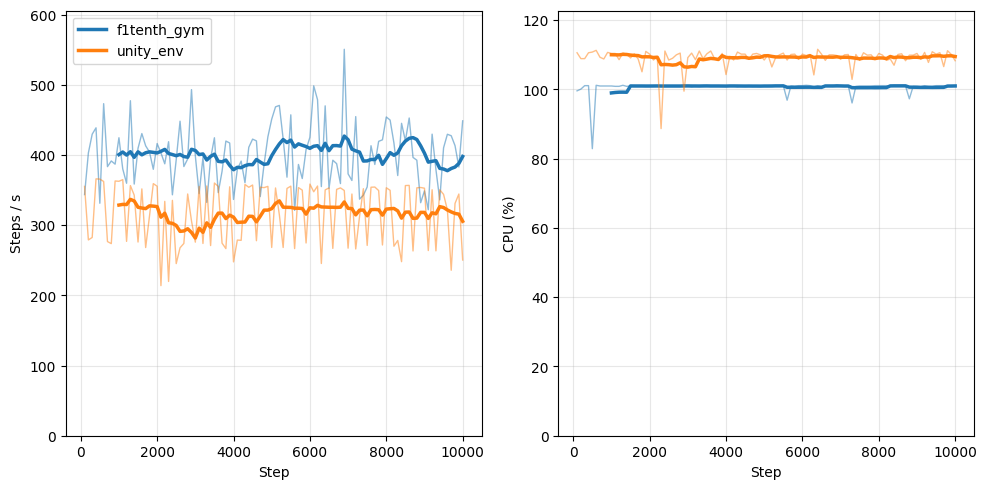

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
metrics = {"sps": "Steps / s", "cpu": "CPU (%)"}
runs = {"f1tenth_gym": f1tenth_env_benchmark, "unity_env": unity_env_benchmark}

for ax, (key, label) in zip(axes, metrics.items()):
    for (name, log), color in zip(runs.items(), plt.rcParams["axes.prop_cycle"].by_key()["color"]):
        vals = pd.Series(log[key])
        ax.plot(log["step"], vals, color=color, alpha=0.5, lw=1)
        ax.plot(log["step"], vals.rolling(10).mean(), color=color, lw=2.5, label=name)
    ax.set(xlabel="Step", ylabel=label, ylim=(0, 1.1 * max(max(log[key]) for log in runs.values())))
    ax.grid(alpha=0.3)

axes[0].legend()
fig.tight_layout()
fig.savefig("results/sim_benchmarks.pdf")

In [12]:
unity_env_benchmark['sps'].mean() /  \
f1tenth_env_benchmark['sps'].mean()

np.float64(0.8141481848938102)